## CS328 Assignment 3: Exercise Recognition and Rep Counting

The objective of this assignment is to build a complete pipeline for exercise recognition from phone accelerometer data. Fitness trackers and gym apps do this every day: they find when you are exercising, recognize the exercise, and count your reps. In this assignment, you will be working with the accelerometer data the class collected with Sensor Logger in the Exercises Study. Each recording is one set of one of eight exercises: squats, jumping jacks, push-ups, sit-ups, ab crunches, lunges, bicep curls, and lat raises.

You will get hands-on experience in several key aspects of mobile health sensing:
1. **Segmentation**: finding the exercise set inside a recording, and ignoring the rest and the phone handling at the start and the end.
2. **Rep counting**: turning the set into a number of reps with peak detection, on the right signal.
3. **Classification**: windowing, feature extraction, and model training, and combining the window predictions into one label per recording.
4. **Error analysis**: finding out which step of the pipeline caused each error.

Unlike A2, where every second of a recording was the same activity, an exercise recording has a beginning, an end, and separate reps in between. Errors also compound: if the segmentation keeps the phone handling, the rep counter counts it as reps, and the classifier sees windows that are not the exercise.

#### Imports Block

Make sure all imports are in this block below.

In [1]:
# -- IMPORTS START --
import pandas as pd
import glob
import os
import numpy as np
import matplotlib.pyplot as plt

from baseline import run_baseline

from sklearn import tree, metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from scipy.signal import butter, filtfilt, find_peaks
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from util import (viz_tree, load_manifest, split_recordings, load_recording, prepare_recording,
                  calc_magnitude, remove_noise, add_features, baseline_features, no_segment,
                  baseline_segment, cut_segment, baseline_count_reps, build_feature_frames,
                  select_recordings, evaluate_rep_counter, rep_metrics, plot_segment)
# -- IMPORTS END --

# enable zooming into graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = [9, 6] # width, height in inches

#### About the data (read this before you start)

- **`data/manifest.csv`** has one row per recording: `path` (e.g., `data/squats/001_2026-09-10_01-40-18.csv`, a number and the date and time of the recording), `exercise`, `reps` (the number of reps the student counted), and `placement` (Hand, Trouser, Jacket, Armband, Bag/backpack).
- Each CSV is the Sensor Logger `Accelerometer` sensor: **linear acceleration in m/s² with gravity removed** (as in A2). `load_recording` returns `time` in seconds from the start of the recording, and the `x`, `y`, `z` axes.
- Most phones log at ~100 Hz, but a few recordings are at 50-60 Hz. Use the `sample_rate` that `load_recording` returns instead of hard-coding it.
- The protocol was: stand still ~5 s → do the set → stand still ~5 s → Stop. **Not everyone did this.** Many recordings start and end with phone handling (putting the phone in a pocket, taking it out to tap Stop), which looks like a short burst of large motion.
- **Placement matters.** With the phone in a trouser pocket, upper-body exercises (bicep curls, lat raises) barely move the phone, and some recordings are almost flat.
- **Reps are self-reported.** Most are right, but some may be off by a rep or two.
- **Some classes are small**: lat raises has 19 recordings and ab crunches 28, while squats has 106.

**Hint (why the magnitude is not enough for counting):** in a squat, going down and coming up both accelerate the phone, so the magnitude often has two peaks per rep. One axis (or the direction that moves the most) has one cycle per rep.

#### Helper functions (provided in util.py, do not modify)

| Function | What it does |
|-|-|
| `load_manifest(root)` | Reads `data/manifest.csv` |
| `split_recordings(manifest, test_size, random_state)` | Splits **recordings** (not windows) into two parts, with the same mix of exercises in both |
| `prepare_recording(path)` | `load_recording` → `calc_magnitude` → `remove_noise`. Returns `data` (columns `time`, `x`, `y`, `z`, `accel_mag`, `filtered_accel_mag`) and `sample_rate` |
| `no_segment(data, sample_rate)` | The whole recording, as `(start_sec, end_sec)` |
| `baseline_segment(data, sample_rate)` | Baseline segmentation: active where the 1 s moving std of `filtered_accel_mag` is above 0.5 m/s². Returns `(start_sec, end_sec)` from the first to the last active sample |
| `cut_segment(data, start_sec, end_sec)` | Keeps only the samples inside the segment |
| `baseline_count_reps(data, sample_rate, exercise)` | Baseline rep counter (A1-style): peaks of `filtered_accel_mag` above its mean, at least 1 s apart |
| `baseline_features(window, sample_rate)` | The 7 A2 baseline features (`add_features`) |
| `build_feature_frames(manifest, window_sec, segment_fn, feature_fn)` | For every recording: `prepare_recording` → `segment_fn` → `cut_segment` → windows of `window_sec` with 50% overlap → `feature_fn`. One row per window, plus the `exercise` and `recording` columns |
| `select_recordings(frames, manifest)` | Keeps only the windows of the recordings in `manifest` |
| `evaluate_rep_counter(manifest, segment_fn, count_fn)` | Runs `segment_fn` and `count_fn` on every recording. One row per recording with `true_reps`, `pred_reps`, and `error` (= pred − true) |
| `rep_metrics(results, by=None)` | `MAE` (mean absolute error in reps), `within_2` (share of recordings within ±2 reps), `bias` (above 0 = counting too many). Use `by='exercise'` or `by='placement'` for a breakdown |
| `plot_segment(data, segments, title)` | Plots `filtered_accel_mag` with one shaded span per segmentation, e.g. `{'baseline': (start_sec, end_sec)}` |

#### Train / validation / test split (provided)

Everyone uses the same split. **Train** recordings (70%) are split again into **fit** and **validation** recordings. Use fit and validation to choose your segmentation, window length, features, hyperparameters, and rep-counting settings. Use the **test** recordings only for the final numbers in the tables. Never pick a setting because it looks better on test.

**Note:** the validation set is small (76 recordings). With a different `random_state` in the split, the same model can score several points higher or lower, so a difference of a few points between two settings may just be noise. Only trust clear differences.

In [2]:
manifest = load_manifest('./data')
train_manifest, test_manifest = split_recordings(manifest, test_size=0.3, random_state=42)
fit_manifest, val_manifest = split_recordings(train_manifest, test_size=0.25, random_state=42)

print('train:', len(train_manifest), '| test:', len(test_manifest),
      '| fit:', len(fit_manifest), '| validation:', len(val_manifest))
manifest.groupby('exercise').size()

train: 301 | test: 129 | fit: 225 | validation: 76


exercise
Ab crunches       28
Bicep curls       50
Jumping jacks     87
Lat raises        19
Lunges            42
Push-ups          58
Sit-ups           40
Squats           106
dtype: int64

Lat raises | placement: Hand | reps: 19 | sample rate: 100 Hz


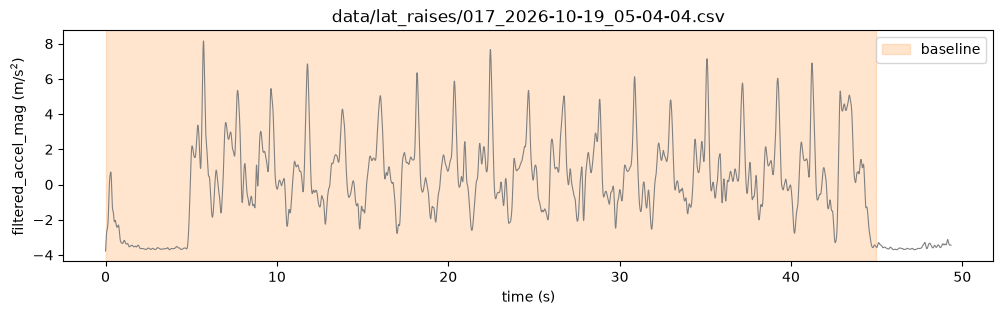

In [3]:
# Example: one recording with the baseline segmentation
row = fit_manifest.iloc[0]  # Inspect a fit recording; reserve test for final evaluation.
data, sample_rate = prepare_recording(row['path'])
print(row['exercise'], '| placement:', row['placement'], '| reps:', row['reps'], '| sample rate: %.0f Hz' % sample_rate)
plot_segment(data, {'baseline': baseline_segment(data, sample_rate)}, title=row['path'])

###  Assignment: Function 1: find_exercise_segment(data, sample_rate)

**Instructions:**
Define the `find_exercise_segment` function that finds the exercise set inside one recording. This is the **segmentation** axis in RUBRIC.md (exploration report §1).

- The function takes as arguments:
  - `data`: a DataFrame with the columns `time` (seconds), `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag` (from `prepare_recording`)
  - `sample_rate`: the sampling frequency of the recording
- The function returns `(start_sec, end_sec)`: the start and the end of the set, in seconds.

**Hints and Instructions:**
- As provided, the function returns the baseline segmentation, so you can run the whole notebook before writing it. Look at the plots: the baseline often keeps the phone handling at both ends, because a fixed threshold of 0.5 m/s² is easy to cross.
- Ideas to try:
  - **Protocol-based**: the protocol asks for ~5 s of standing still at both ends, so drop the first and the last few seconds. Simple, but it cuts reps when someone did not stand still.
  - **Adaptive threshold**: set the threshold from the recording itself, e.g., between its quiet level (a low percentile of the moving std) and its active level (a high percentile), instead of a fixed 0.5 m/s².
  - **Ignore short bursts**: phone handling lasts 1-2 s, while a set lasts much longer. Drop active parts shorter than a few seconds, or keep only the longest one.
  - **Use the rep band**: reps are slow (one every 1-4 s), while handling is short and sharp. Band-pass the signal to ~0.2-1.5 Hz before measuring the energy.
- Compare the baseline with **at least one approach of your own** (exploration report §1). Write each approach as its own function with the same two arguments, so you can pass it to `evaluate_rep_counter` and `build_feature_frames`. Keep the best one as `find_exercise_segment`. You will measure the effect of segmentation in the rep counting and classification sections.

In [4]:
def find_exercise_segment(data, sample_rate):
    start_sec, end_sec = baseline_segment(data, sample_rate)   # baseline: fixed threshold

    ######## TODO ###############
    # Replace the baseline with your own segmentation
    #############################

    return start_sec, end_sec

## Assignment-Segmentation: Visual Check

1. **Plot** at least **6 recordings** from `fit_manifest` with different exercises and placements, with the baseline and your segmentation, e.g. `plot_segment(data, {'baseline': ..., 'yours': ...})`.

2. **Find** one recording where the baseline fails and one where your method fails. Use them in §1 of your exploration report.

3. **Interpretation of the results**: What does the baseline get wrong? What does your method fix, and where does it still break?

In [5]:
# Hints, step by step:
# Pick recordings from fit_manifest, e.g. fit_manifest.groupby('placement').head(2)
# data, sample_rate = prepare_recording(row['path'])
# plot_segment(data, {'baseline': baseline_segment(data, sample_rate),
#                     'yours': find_exercise_segment(data, sample_rate)}, title=...)

########################### TODO ##########################

#### 🛑 Interpretation of the results

**Write Below:**

###  Assignment: Function 2: count_reps(data, sample_rate, exercise)

**Instructions:**
Define the `count_reps` function that counts the reps in one set. This is the **rep counting** axis in RUBRIC.md (exploration report §3).

- The function takes as arguments:
  - `data`: the **segment** only (already cut with the segmentation), with the same columns as above
  - `sample_rate`: the sampling frequency of the recording
  - `exercise`: the exercise name from the manifest (e.g., `'Squats'`), so you can use exercise-specific settings
- The function returns the number of reps (an integer).

**Hints and Instructions:**
- As provided, the function returns the baseline count (A1-style peaks on `filtered_accel_mag`). It counts far too many reps: for many exercises the magnitude has two peaks per rep, and noise adds more.
- Ideas to try:
  - **Pick a better signal**: one axis (e.g., the one with the largest std in the segment), or the direction that moves the most (the first principal component of `x`, `y`, `z`, e.g., with `np.linalg.svd`).
  - **Low-pass harder**: reps are slow, one every 1-4 s (0.25-1 Hz). A cutoff around 1-1.5 Hz removes most of the extra peaks.
  - **Minimum distance between peaks**: set `distance` in `find_peaks` from the rep period. You can estimate the period with the autocorrelation of the signal, or use the typical time per rep of each exercise in the training recordings (segment length / reps).
  - **Prominence**: set `prominence` relative to the std of the signal, so small bumps are not counted.
  - **Exercise-specific settings**: e.g., the typical time per rep is different for each exercise.
  - **Placement effects**: `count_reps` does not get the placement. E.g., with the phone in a pocket, a jumping jack has two jumps (feet out, feet in) per rep. A low-pass filter around 1 Hz mostly merges them into one cycle per rep.
- Tune on the training recordings only (fit + validation), never on test.

In [6]:
def count_reps(data, sample_rate, exercise):
    reps = baseline_count_reps(data, sample_rate, exercise)   # baseline: peaks of filtered_accel_mag

    ######## TODO ###############
    # Replace the baseline with your own rep counter
    #############################

    return reps

## Assignment-Rep Counting: Evaluate Segmentation and Rep Counting

`evaluate_rep_counter(manifest, segment_fn, count_fn)` runs a segmentation and a rep counter on every recording of `manifest` (using the true exercise from the manifest), and `rep_metrics` summarizes the errors.

1. **Baseline**: evaluate `baseline_segment` + `baseline_count_reps` on the training recordings (`train_manifest`).

2. **Tune**: improve `count_reps` and `find_exercise_segment` on the training recordings. Use `rep_metrics(results, by='exercise')` and `rep_metrics(results, by='placement')` to see where the errors are, and `bias` to see if you count too many or too few.

3. **Test**: when you are done tuning, evaluate each combination in the table below on `test_manifest` (`no_segment` = the whole recording). For §1 of your report, also evaluate the other segmentation approaches you tried, with your rep counter.

4. **Fill up** these tables.

5. **Interpretation of the results**: How much did segmentation help, and how much did the rep counter help? Which exercises and placements are hardest to count, and why?

In [7]:
# Hints, step by step:
# results = evaluate_rep_counter(train_manifest, baseline_segment, baseline_count_reps)
# rep_metrics(results), rep_metrics(results, by='exercise'), rep_metrics(results, by='placement')
# Tune count_reps and find_exercise_segment on train_manifest
# Finally, evaluate each combination in the table on test_manifest

########################### TODO ##########################

**For the test recordings:**

| Segmentation | Rep counter | MAE (reps) | Within ±2 reps | Bias |
|-|-|-|-|-|
| none (`no_segment`) | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| baseline | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| yours | baseline | **FILL UP** | **FILL UP** | **FILL UP** |
| baseline | yours | **FILL UP** | **FILL UP** | **FILL UP** |
| yours | yours | **FILL UP** | **FILL UP** | **FILL UP** |

**Your segmentation + your rep counter, by placement (test recordings):**

| Placement | Recordings | MAE (reps) | Within ±2 reps |
|-|-|-|-|
| Hand | **FILL UP** | **FILL UP** | **FILL UP** |
| Trouser | **FILL UP** | **FILL UP** | **FILL UP** |
| Jacket | **FILL UP** | **FILL UP** | **FILL UP** |
| Armband | **FILL UP** | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results

**Write Below:**

###  Assignment: Function 3: add_my_features(window, sample_rate)

This is where you do your **feature engineering** (exploration report §2). The function receives one window and returns a one-row DataFrame of features.

**Hints and Instructions:**
- The window has the columns `time`, `x`, `y`, `z`, `accel_mag`, and `filtered_accel_mag`.
- Start from the baseline features in `add_features` (7 statistics of the filtered magnitude, from A2) and add your own as new columns. As provided, the function only returns the baseline, so you can run the whole notebook before writing any features.
- Ideas to try:
  - **Which axis moves**: std of `x`, `y`, `z`, and the share of the largest one (a bicep curl in the hand moves mostly along one axis; a jumping jack moves along all of them)
  - **Rep rate**: dominant frequency of the filtered magnitude or of one axis (use `np.fft.rfft` and `np.fft.rfftfreq(len(signal), 1/sample_rate)`). Jumping jacks are fast, squats are slow
  - **Correlation between axes**: `np.corrcoef`
  - **Intensity**: RMS, range, number of peaks per second
- Gravity is removed, so the features cannot directly tell lying down (sit-ups) from standing (squats).
- Some features can be `NaN` (e.g., the correlation of a flat window). Return 0 instead, because most models cannot handle `NaN`.
- Aim for ~5-10 features of your own on top of the 7 baseline features. Keep the ones that help and document the ones you dropped.

In [8]:
def add_my_features(window, sample_rate):
    features = add_features(window)   # baseline: avg, max, med, min, q25, q75, std of filtered_accel_mag

    ######## TODO ###############
    # Add your own features as new columns, e.g.
    # features['std_x'] = ...
    #############################

    return features

#### Helper functions (provided)

`train_decision_tree`, `train_random_forest`, and `evaluate` take an optional `features` argument (a list of column names). By default, the training functions use every feature column (everything except `exercise` and `recording`), and `evaluate` uses the same columns the model was trained on. Unlike A2, the training functions do not split the data. You pass them the training windows, and then you evaluate on other recordings with `evaluate`.

Use `train_random_forest` (fixed settings) to compare window lengths, features, and segmentation. Use `train_decision_tree` in Classification1.

In [9]:
BASELINE_FEATURES = ['avg', 'max', 'med', 'min', 'q25', 'q75', 'std']

def feature_columns(frames):
    return [c for c in frames.columns if c not in ('exercise', 'recording')]


def evaluate(model, frames, features=None, verbose=True):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))
    X_test = frames[list(features)]

    # Extract target column
    y_test = frames['exercise']

    pred = model.predict(X_test)
    acc = accuracy_score(y_test, pred)
    if verbose:
        print(classification_report(y_test, pred, zero_division=0))
        print("Accuracy:", acc)
    return acc, pred

In [10]:
def train_decision_tree(frames, max_depth=5, criterion='entropy', features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # Create and train the model on all the windows in frames
    dt_model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=42).fit(X, y)
    return dt_model


def train_random_forest(frames, features=None):
    # Extract feature columns
    if features is None:
        features = feature_columns(frames)
    X = frames[list(features)]

    # Extract target column
    y = frames['exercise']

    # A random forest with fixed settings, to compare window lengths, features, and segmentation
    rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X, y)
    return rf_model

## Step 1: Measure the supplied baselines

Run this section before improving any methods. It uses the prescribed recording
split and checks that fit, validation, and test recordings do not overlap.

- **Counting:** supplied segmentation + supplied counter, evaluated on the 301
  training recordings. Results are also broken down by exercise and placement.
- **Classification:** supplied segmentation, 4-second windows with 50% overlap,
  and the seven supplied features. Train the default Decision Tree and Random
  Forest on 225 fit recordings; evaluate windows from 76 validation recordings.
- **Test:** save the split membership, but do not evaluate test predictions yet.

Four seconds is a starting point, not a tuned choice. These are development
results, not the final test results requested in the assignment tables.
The helper `baseline.py` saves the full results in `results/step1_baseline/`.
Our explanations and next steps are in `WORK_LOG.md`.


In [11]:
baseline_results = run_baseline()

print("Rep counting (within_2 is a fraction; bias = predicted minus reported):")
display(pd.DataFrame(baseline_results['rep_counting']).T.round(4))

print("Classification (validation windows only):")
display(pd.DataFrame(baseline_results['classification'])[
    ['model', 'fit_windows', 'validation_windows', 'validation_window_accuracy']
].round(4))


Recordings: {'train': 301, 'fit': 225, 'validation': 76, 'test': 129}


Counting repetitions on the 301 training recordings...
Building baseline features for training recordings only...
Fitting Decision Tree; evaluating validation windows...
Fitting Random Forest; evaluating validation windows...
Training rep metrics: {'recordings': 301, 'MAE': 7.980066445182724, 'within_2': 0.19601328903654486, 'bias': 4.6112956810631225}
Decision Tree validation window accuracy: 41.87%
Random Forest validation window accuracy: 46.80%
Results saved in results/step1_baseline
Rep counting (within_2 is a fraction; bias = predicted minus reported):


,recordings,MAE,within_2,bias
train,301.0,7.9801,0.1960,4.6113
fit,225.0,7.9778,0.2133,4.8044
validation,76.0,7.9868,0.1447,4.0395


Classification (validation windows only):


,model,fit_windows,validation_windows,validation_window_accuracy
0,Decision Tree,3677,1156,0.4187
1,Random Forest,3677,1156,0.4680


### What the Step 1 results mean

With the supplied methods, training repetition-count MAE is **7.98 reps**,
**19.60%** of recordings are within two reps, and bias is **+4.61 reps**.
The counter overcounts overall, but jumping jacks are undercounted on average.
We need to inspect traces before attributing those errors to a particular cause.

On the 76 validation recordings (1,156 windows), the default Decision Tree
reaches **41.87%** window accuracy and the default Random Forest **46.80%**.
These are starting measurements, not tuned results or final test scores.

The full breakdowns, limitations, and reproduction commands are recorded in
`WORK_LOG.md`. Next we will compare segmentation methods on training data.


## Assignment-Feature Exploration: Window Length, Features, and Segmentation

Before comparing models, choose the window length and the feature set (exploration report §2), and check the effect of your segmentation on classification (§1). Train with `train_random_forest` on the **fit** windows and evaluate on the **validation** windows. We use a random forest here because it uses many features at once, so the effect of a feature set is easier to see than with a small decision tree.

`build_feature_frames` goes over all 430 recordings (about 1-2 minutes). Build it once per setting for the whole `manifest`, then use `select_recordings` to get the fit, validation, and test windows.

1. **Window length**: Build the feature frames with at least three window lengths (e.g., 2 s, 4 s, 6 s), using `find_exercise_segment` and the baseline features (`baseline_features`). Train on fit, evaluate on validation.

2. **Features**: Write `add_my_features` (Function 3) and rebuild. Compare the baseline features to your features at the same window length. Try adding and removing features (pass `features=[...]` to `train_random_forest`) and use the classification report to see which exercises each feature helps.

3. **Segmentation**: Rebuild with your features and `no_segment` instead of `find_exercise_segment`, and compare.

4. **Lock in** one window length, one feature set, and one segmentation, and use them in all the sections below.

5. **Fill up** this table.

6. **Interpretation of the results**: Which window length worked best, and why do you think so? Which features helped, and which exercises did they separate? Did segmentation help the classifier?

In [12]:
# Hints, step by step:
# frames = build_feature_frames(manifest, 4, find_exercise_segment, baseline_features)
# fit_frames, val_frames = select_recordings(frames, fit_manifest), select_recordings(frames, val_manifest)
# model = train_random_forest(fit_frames, features=BASELINE_FEATURES); evaluate(model, val_frames)
# Repeat for other window lengths, then with add_my_features, then with no_segment
# Lock in WINDOW_SEC and your final frames, then for the rest of the notebook:
#   FEATURES = feature_columns(frames)
#   train_frames, test_frames = select_recordings(frames, train_manifest), select_recordings(frames, test_manifest)

########################### TODO ##########################

**For the validation recordings:**

| Segmentation | Window length | Features | Window accuracy (validation) |
|-|-|-|-|
| yours | 2 s | baseline | **FILL UP** |
| yours | 4 s | baseline | **FILL UP** |
| yours | 6 s | baseline | **FILL UP** |
| yours | **FILL UP** s | **FILL UP your features** | **FILL UP** |
| none | **FILL UP** s | **FILL UP your features** | **FILL UP** |


#### 🛑 Interpretation of the results

**Write Below:**

## Assignment-Classification1: Decision Tree

In this section, you tune a decision tree and test it on the test recordings. The steps are as follows:

1. **Grid Search**: Do grid search for tuning the hyperparameters (`max_depth` and `criterion` in `train_decision_tree`). Train on the **fit** windows and pick the hyperparameters with the highest accuracy on the **validation** windows. Do not pick hyperparameters by looking at the test accuracy: it is your test set.

2. **Test**: Retrain the decision tree with the best hyperparameters on all the **training** windows (fit + validation), and evaluate it on the **test** windows. Do the same for the default hyperparameters.

3. **Performance Visualization**: Display the confusion matrix of the test windows with matplotlib's `ConfusionMatrixDisplay`. Each row corresponds to a true exercise, and each column to a predicted exercise. With 8 exercises, use a large figure and rotate the labels (`xticks_rotation='vertical'`).

4. **Decision Tree Visualization**: Visualize the decision tree using the `viz_tree` function (loaded from util.py). Pass `list(model.classes_)` as the class names, so the names match the model's order of the classes.

5. **Fill up** this table.

6. **Interpretation of the results**: Which exercises are easy to recognize, and which are confused with each other? Why? What did you learn from hyperparameter tuning?

In [13]:
# Hints, step by step:
# Grid search: for each max_depth and criterion, train on fit_frames, evaluate on val_frames (verbose=False)
# Retrain the best (and the default) on train_frames, evaluate on test_frames
# Display the confusion matrix of the test windows
# Visualize the tree: viz_tree(model, train_frames[FEATURES], list(model.classes_))

########################### TODO ##########################

**For the data in the dataset:**

| Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|-|-|-|
| Default (max_depth=5, criterion='entropy') | **FILL UP** | **FILL UP** |
| **FILL UP best hyperparameters**  | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results

**Write Below:**

## Assignment-Classification2: A New Classifier

Repeat section Assignment-Classification1 with a different classifier, using the same window length and feature set. It could be Random Forest, kNN, Logistic regression, or any other classifier of your choice (add its import to the imports block). Tune its key hyperparameters the same way (fit → validation), then retrain on all the training windows and evaluate on the test windows. Finally, compare it with the decision tree (model exploration, exploration report §2): did the better model help all exercises equally, or did the gain concentrate on specific exercises?

Notes:
- kNN, Logistic Regression, and SVM are sensitive to feature scale, so standardize the features first (e.g., `make_pipeline(StandardScaler(), KNeighborsClassifier())`).
- The classes are imbalanced (106 squats vs 19 lat raises). Many models have `class_weight='balanced'`. Try it and see what happens to the small classes.

In [14]:
# Hints, step by step:
# Grid search the key hyperparameters of the new classifier: fit on fit_frames[FEATURES], evaluate on val_frames
# Retrain the best on train_frames, evaluate on test_frames
# Display the confusion matrix
# Visualize the model if it makes sense (feature importances for a forest)

########################### TODO ##########################

**For the data in the dataset:**

| Model | Hyperparameters | Window accuracy (validation) | Window accuracy (test) |
|-|-|-|-|
| **FILL UP your new classifier** | **FILL UP best hyperparameters** | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results and comparison to the decision tree.

**Write Below:**

###  Assignment: Function 4: predict_recordings(model, frames, features)

So far every accuracy is a **window** accuracy. A real app gives one answer per recording, so aggregate the window predictions of each recording into one label (exploration report §4).

**Hints and Instructions:**
- The function takes as arguments:
  - `model`: a trained classifier
  - `frames`: a feature DataFrame with the `exercise` and `recording` columns
  - `features`: the feature columns the model was trained on
- The function will perform the following:
  - Predict the label of every window
  - Group the predictions by `recording` and take the most common label (majority vote). You may also try confidence-weighting with `model.predict_proba`.
  - Return a DataFrame with one row per recording and the columns `recording`, `true`, and `predicted`

In [15]:
def predict_recordings(model, frames, features=None):
    # By default, use the same columns the model was trained on
    if features is None:
        features = getattr(model, 'feature_names_in_', feature_columns(frames))

    ######## TODO ###############
    pass
    #############################

    return recordings

## Assignment-Recording-Level Predictions

A real app gives one answer per recording. In this section, you combine the window predictions of each **test** recording into one exercise label.

1. **Recording-level accuracy**: Use `predict_recordings` with your best decision tree and your best new classifier (both trained on all the training windows) on the test windows. Recording-level accuracy = `(recordings['true'] == recordings['predicted']).mean()`.

2. **Confusion matrix**: Display the recording-level confusion matrix of your final pipeline. You will use it in §4 of your exploration report.

3. **Fill up** this table.

4. **Interpretation of the results**: Does the majority vote help? For which exercises? When can it make things worse?

In [16]:
# Hints, step by step:
# recordings = predict_recordings(model, test_frames)
# Recording-level accuracy = (recordings['true'] == recordings['predicted']).mean()
# Display the confusion matrix of the recording-level predictions

########################### TODO ##########################

**For the test recordings:**

| Model | Window accuracy | Recording accuracy |
|-|-|-|
| Decision Tree (best) | **FILL UP** | **FILL UP** |
| **FILL UP your new classifier** (best) | **FILL UP** | **FILL UP** |


#### 🛑 Interpretation of the results

**Write Below:**

## Assignment-Failure Analysis (for exploration report §4 and §5)

Pick your final pipeline (exploration report §4) and look at where it fails.

1. **Classification errors**: From the recording-level confusion matrix, find the largest off-diagonal cells (e.g., lat raises predicted as squats). For each one, decide whether it is a **segmentation** problem (the segment is wrong), a **feature** problem (the features do not separate the two exercises), or a **model** problem (the features separate them, but the model fails, e.g., because the class is small).

2. **Rep counting errors**: Find the test recordings with the largest rep errors. Is it the segmentation (phone handling counted as reps, reps cut off), the counting (two peaks per rep, small reps missed), or the label (a wrong reported count)?

3. **Placement**: Merge with `test_manifest` to get the `placement` of each recording. Are the failures concentrated in one placement?

4. **Figures**: For your **top 2 failure modes**, plot one recording with your segment (`plot_segment`). For a rep-counting failure, also plot the signal you count on with the detected peaks. For a classification failure, compare its feature values to the typical (median) feature values of the correct and of the predicted exercise.

Use these figures in §5 of your exploration report.

In [17]:
# Hints, step by step:
# Wrong recordings: recordings[recordings['true'] != recordings['predicted']]
# Placement: test_manifest.merge(recordings, left_on='path', right_on='recording')
# rep_results = evaluate_rep_counter(test_manifest, find_exercise_segment, count_reps)
# Largest rep errors: rep_results.sort_values('error', key=abs, ascending=False).head(10)
# Plot: data, sample_rate = prepare_recording(path); plot_segment(data, {'yours': find_exercise_segment(data, sample_rate)})
# To plot your detected reps, copy the inside of count_reps into a cell and plot the signal with the peaks
# Compare: train_frames.groupby('exercise')[FEATURES].median() vs the feature values of the failing recording

########################### TODO ##########################

#### 🛑 Top 2 failure modes

**Write Below:**